In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
from scipy.stats import chi2_contingency

In [3]:
conn = sqlite3.connect("boxscore_ai.db")
df = pd.read_sql("SELECT * FROM games", conn)
conn.close()

### Data Health & Summary Statistics

In [4]:
df.shape

(2460, 22)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2460 entries, 0 to 2459
Data columns (total 22 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   GAME_ID            2460 non-null   int64  
 1   TEAM_ID            2460 non-null   int64  
 2   SEASON_ID          2460 non-null   int64  
 3   GAME_DATE          2460 non-null   object 
 4   TEAM_ABBREVIATION  2460 non-null   object 
 5   MATCHUP            2460 non-null   object 
 6   WL                 2460 non-null   object 
 7   PTS                2460 non-null   int64  
 8   AST                2460 non-null   int64  
 9   STL                2460 non-null   int64  
 10  BLK                2460 non-null   int64  
 11  TOV                2460 non-null   int64  
 12  FGM                2460 non-null   int64  
 13  FGA                2460 non-null   int64  
 14  FG_PCT             2460 non-null   float64
 15  FG3M               2460 non-null   int64  
 16  FG3A               2460 

In [7]:
# Basic summary metrics
df.describe().T

,count,mean,std,min,25%,50%,75%,max
GAME_ID,2460.0,2.240062e+07,355.142489,2.240000e+07,2.240031e+07,2.240062e+07,2.240092e+07,2.240123e+07
TEAM_ID,2460.0,1.610613e+09,8.657201,1.610613e+09,1.610613e+09,1.610613e+09,1.610613e+09,1.610613e+09
SEASON_ID,2460.0,2.202400e+04,0.000000,2.202400e+04,2.202400e+04,2.202400e+04,2.202400e+04,2.202400e+04
PTS,2460.0,1.138252e+02,12.711950,6.700000e+01,1.050000e+02,1.140000e+02,1.220000e+02,1.620000e+02
AST,2460.0,2.654959e+01,5.288003,9.000000e+00,2.300000e+01,2.600000e+01,3.000000e+01,4.800000e+01
STL,2460.0,8.204878e+00,3.089734,1.000000e+00,6.000000e+00,8.000000e+00,1.000000e+01,2.200000e+01
BLK,2460.0,4.876016e+00,2.457047,0.000000e+00,3.000000e+00,5.000000e+00,6.000000e+00,1.800000e+01
TOV,2460.0,1.429837e+01,4.027811,3.000000e+00,1.100000e+01,1.400000e+01,1.700000e+01,3.100000e+01
FGM,2460.0,4.169350e+01,5.266732,2.200000e+01,3.800000e+01,4.200000e+01,4.500000e+01,6.000000e+01
FGA,2460.0,8.923862e+01,7.290212,6.700000e+01,8.400000e+01,8.900000e+01,9.400000e+01,1.190000e+02


In [8]:
# Check for missing value counts
df.columns.tolist()
df.isnull().sum()

GAME_ID              0
TEAM_ID              0
SEASON_ID            0
GAME_DATE            0
TEAM_ABBREVIATION    0
MATCHUP              0
WL                   0
PTS                  0
AST                  0
STL                  0
BLK                  0
TOV                  0
FGM                  0
FGA                  0
FG_PCT               0
FG3M                 0
FG3A                 0
FTM                  0
FTA                  0
OREB                 0
DREB                 0
REB                  0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(0)

### Univariate Analysis

In [10]:
game_points = df["PTS"]
df_points = game_points.to_frame("points")
df_points.shape

(2460, 1)

<Axes: xlabel='points', ylabel='Count'>

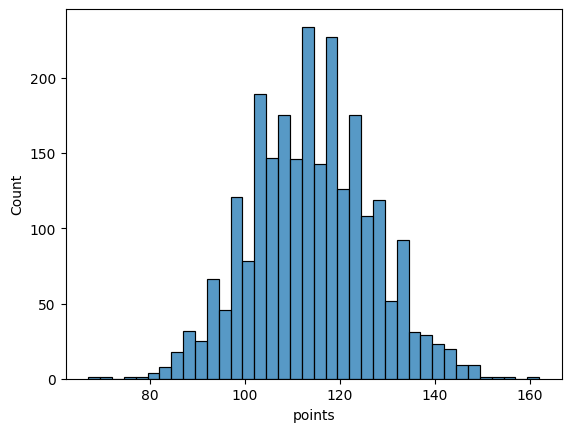

In [11]:
sns.histplot(data=df_points, x="points")    # this is a bell curve, normally distributed

In [12]:
min_val = df_points["points"].min()
max_val = df_points["points"].max()
median = df_points["points"].median()
q1 = df_points["points"].quantile(0.25)
q3 = df_points["points"].quantile(0.75)
iqr = q3-q1
min_outlier = q1-1.5*iqr
max_outlier = q3+1.5*iqr


print(f"Minimum value: {min_val}")
print(f"Maximum value:  {max_val}")
print(f"Median:  {median}")
print(f"Q1:  {q1}")
print(f"Q3:  {q3}")
print(f"IQR: {iqr}")
print(f"Outlier range: [{min_outlier}, {max_outlier}]")

Minimum value: 67
Maximum value:  162
Median:  114.0
Q1:  105.0
Q3:  122.0
IQR: 17.0
Outlier range: [79.5, 147.5]


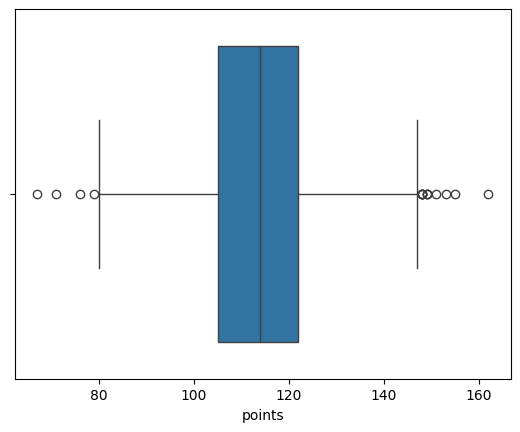

In [13]:
# NOTE: the outliers range are [79.5, 147.5], so the min and max here are considered as outliers. 
# The whiskers edges are on the outliers' range points itself

sns.boxplot(x=df_points["points"])
plt.show()

#### Explanation:

1. Are points normally distributed (bell curve), or is there a skew?

- Points are normally distributed like a bell curve and almost symmetrical. There's no left or right skew.

2. Are there any extreme outliers (e.g. 140+ point games or <70 point games)?

- Yes, based on the box plot and on my calculation of the outliers, there is 4 data points of outliers on the left side that are lower than 79.5 points and 6 data points of the outliers on the right side taht are higher than 147.5 points.

### Bivariate & Multivariate Analysis (Relationships)

In [14]:
# checks whether is being at Home or Away correlates the Wins and Losses
df["is_home"] = np.where(df["MATCHUP"].str.contains("vs.").astype(int),"Home", "Away")
cross_tab = pd.crosstab(df["is_home"], df["WL"])
print(cross_tab)

WL         L    W
is_home          
Away     672  563
Home     558  667


Based on the crosstab table, it can be seen that homecourt advantage really does affect the winning of teams, while being an Away team tend to lose more.

In [15]:
# Category vs category comparison
chi2 = chi2_contingency(cross_tab)
p_value = chi2[1]
print(f"P-value: {p_value:.5f}")

P-value: 0.00001


Since the p-value is almost 0, it is clear that there is a real difference between the home and away games of basketball games

In [16]:
# Category vs number

aggregated_data = df.groupby(["WL"]).agg(
    avg_pts=("PTS", "mean"),
    avg_reb=("REB", "mean"),
    avg_ast=("AST", "mean"),
    avg_fg_pct=("FG_PCT", "mean")
)
print(aggregated_data)

       avg_pts    avg_reb    avg_ast  avg_fg_pct
WL                                              
L   107.451220  42.141463  24.902439    0.444093
W   120.199187  46.082927  28.196748    0.492351


This shows that the winning teams has an average of more points, rebounds, assists, and field goal percentages which contribute to their winning.

In [17]:
# Number vs number
# pearson
df_numerical = df[["PTS", "FG_PCT", "AST", "REB", "OREB", "STL", "BLK", "TOV"]]
df_corr = df_numerical.corr(method="pearson") # it is clearly shown that the pts and fg_pct have high correlation (0.7 < 1)
df_corr

,PTS,FG_PCT,AST,REB,OREB,STL,BLK,TOV
PTS,1.000000,0.725235,0.631723,0.123585,0.023295,0.092918,0.042403,-0.214772
FG_PCT,0.725235,1.000000,0.548313,-0.172477,-0.332787,0.004375,-0.014199,0.012610
AST,0.631723,0.548313,1.000000,0.044954,-0.066872,0.074397,-0.000106,-0.155293
REB,0.123585,-0.172477,0.044954,1.000000,0.591448,-0.137786,0.178549,0.070838
OREB,0.023295,-0.332787,-0.066872,0.591448,1.000000,0.022309,0.034182,0.013757
STL,0.092918,0.004375,0.074397,-0.137786,0.022309,1.000000,0.025632,0.046945
BLK,0.042403,-0.014199,-0.000106,0.178549,0.034182,0.025632,1.000000,0.055844
TOV,-0.214772,0.012610,-0.155293,0.070838,0.013757,0.046945,0.055844,1.000000


<Axes: >

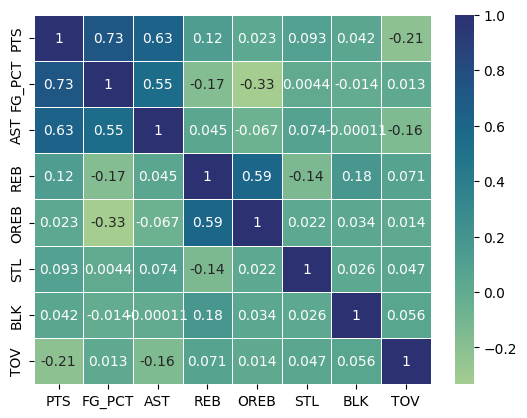

In [18]:
# heaptmap visualization
sns.heatmap(df_corr, cmap="crest", annot=True, linewidths=.5)

#### as shown in the correlation heatmap:
-   ***Points (PTS)*** is very/highly correlated with FG_PCT and AST
-   ***Fieldgoal percentage (FG_PCT)*** is highly correlated with AST
-   ***Rebounds (REB)*** is highly correlated with OREB (Offensive rebounds) as well

#### I didn't conduct a t-test but the top 4 box-score stats which contribute to winning are:
    1. PTS
    2. FG_PCT
    3. AST
    4. REB
    